# Rock vs Mine Prediction

**Goal:** classify a sonar return as a rock (R) or a metal mine (M).

**Data:** 208 samples, each with 60 numbers (the echo energy in 60 frequency bands) and a label. The file has no header row. To run this notebook, upload `Dataset.csv` to Colab (it is read from `/content/Dataset.csv`).

**Approach:** exploratory analysis, stratified train/test split, `RobustScaler`, three models compared (Logistic Regression, SVM, Random Forest), final evaluation on the test set, saved model, and a small Gradio demo.

## Importing the Dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## Data Collection

In [2]:
# Loading the Data
df = pd.read_csv("/content/Dataset.csv", header=None)

# Display Data
print("The Shape of the data is: ", df.shape)
print("\nThe Dataset:")
df.head(8)

The Shape of the data is:  (208, 61)

The Dataset:


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R
5,0.0286,0.0453,0.0277,0.0174,0.0384,0.0990,0.1201,0.1833,0.2105,0.3039,...,0.0045,0.0014,0.0038,0.0013,0.0089,0.0057,0.0027,0.0051,0.0062,R
6,0.0317,0.0956,0.1321,0.1408,0.1674,0.1710,0.0731,0.1401,0.2083,0.3513,...,0.0201,0.0248,0.0131,0.0070,0.0138,0.0092,0.0143,0.0036,0.0103,R
7,0.0519,0.0548,0.0842,0.0319,0.1158,0.0922,0.1027,0.0613,0.1465,0.2838,...,0.0081,0.0120,0.0045,0.0121,0.0097,0.0085,0.0047,0.0048,0.0053,R


In [3]:
# Information
print("\nMissing values:", df.isna().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:\n", df.iloc[:, -1].value_counts())
print("\nFeature dtypes:\n", df.dtypes.value_counts())


Missing values: 0

Duplicate rows: 0

Class counts:
 60
M    111
R     97
Name: count, dtype: int64

Feature dtypes:
 float64    60
object      1
Name: count, dtype: int64


**What we learned about the data**
- 208 samples, 60 numeric features (sonar echo energy in 60 frequency bands) plus one label column.
- No missing values and no duplicate rows.
- The classes are almost balanced: 111 mines (M) and 97 rocks (R), about 53% / 47%, so accuracy is a fair metric and no resampling is needed.

## Exploratory Data Analysis (EDA)

In [4]:
# Define the target and feature columns
target = df.columns[-1]
features = df.columns[:-1]
print("Target column:", target)
print("Number of features:", len(features))

Target column: 60
Number of features: 60


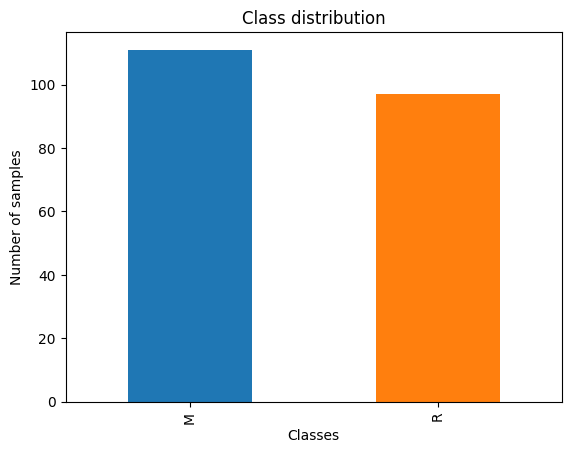

60
M    53.4
R    46.6
Name: count, dtype: float64


In [5]:
# Class balance plot
counts = df[target].value_counts()
counts.plot(kind="bar", color=["tab:blue", "tab:orange"])
plt.title("Class distribution")
plt.ylabel("Number of samples")
plt.xlabel("Classes")
plt.show()

print((counts / len(df) * 100).round(1))

The classes are close to balanced (53.4% mines, 46.6% rocks), so no oversampling or class weighting is needed.

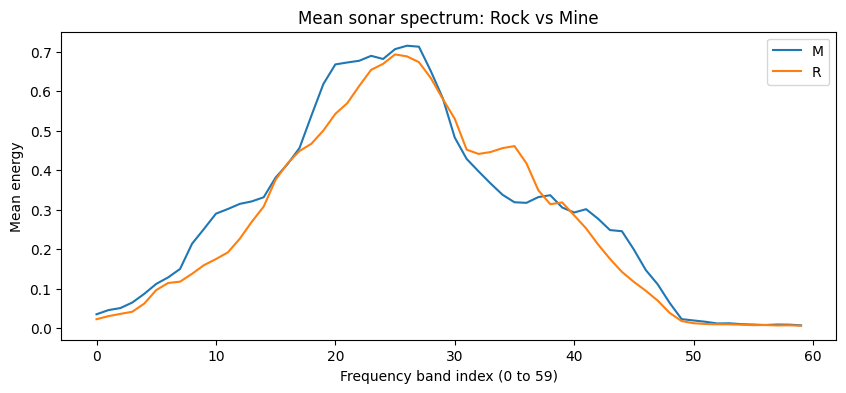

In [6]:
# Mean spectrum per class
mean_spec = df.groupby(target)[features].mean().T   # rows = bands, cols = classes

plt.figure(figsize=(10, 4))
for cls in mean_spec.columns:
    plt.plot(range(60), mean_spec[cls], label=cls)
plt.xlabel("Frequency band index (0 to 59)")
plt.ylabel("Mean energy")
plt.title("Mean sonar spectrum: Rock vs Mine")
plt.legend()
plt.show()

**Reading the plot:** each line is the average echo "fingerprint" of a class across the 60 frequency bands.
- Mines have stronger average echoes in roughly bands 9 to 21.
- Rocks have stronger average echoes around bands 34 to 36.
- The lines overlap in many bands, and individual samples vary a lot around these averages, so the classes are separable but not cleanly.

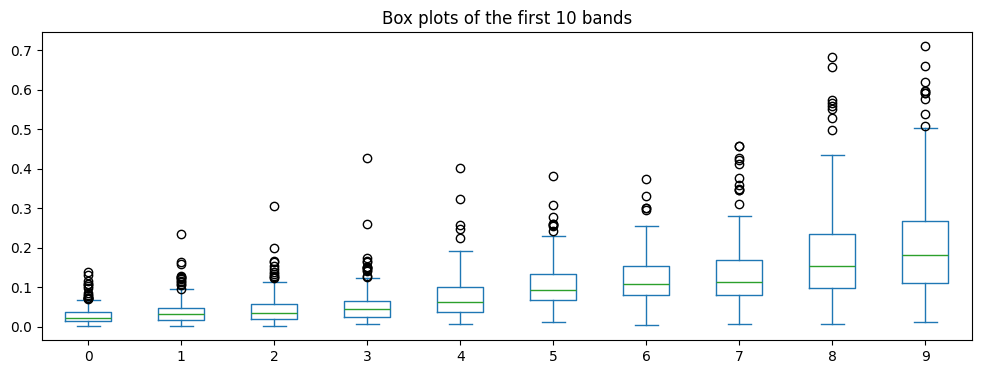

Overall min: 0.0
Overall max: 1.0


In [7]:
# Box plots split by class
df[features].iloc[:, :10].plot(kind="box", figsize=(12, 4))
plt.title("Box plots of the first 10 bands")
plt.show()

print("Overall min:", df[features].min().min())
print("Overall max:", df[features].max().max())

**Outliers:** the box plots show some outliers, but all values lie between 0 and 1. They look like genuine sonar measurements, not errors, and with only 208 rows deleting samples would cost too much data. They are kept, and `RobustScaler` is used later because it is less affected by extreme values.

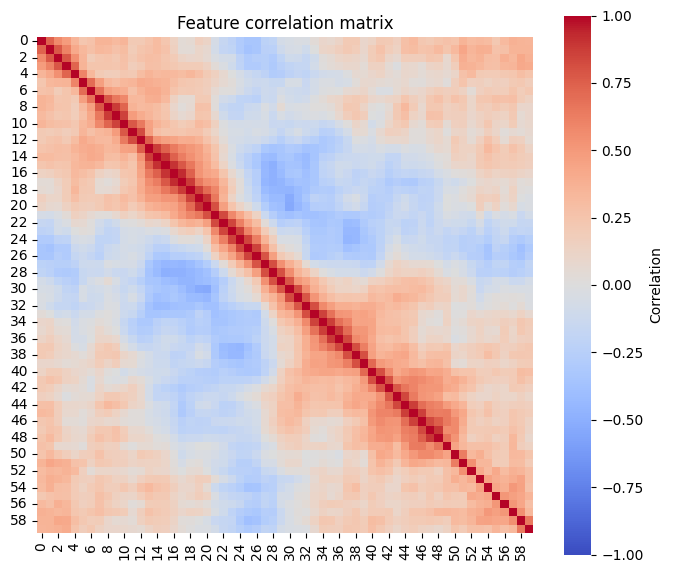

In [8]:
# Correlation heatmap
plt.figure(figsize=(8, 7))
sns.heatmap(df[features].corr(), cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"label": "Correlation"})
plt.title("Feature correlation matrix")
plt.show()

**Correlation:** neighboring frequency bands are strongly correlated, so the 60 features carry less independent information than their number suggests. This is one reason simple or regularized models can work well on this data.

## Train/Test Split

In [9]:
X = df[features]
y = df[target].map({"R": 0, "M": 1})    # rock = 0, mine = 1

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

(156, 60) (52, 60)


The data is split 75% / 25% (156 training rows, 52 test rows) with `stratify=y`, so both parts keep the same rock/mine ratio. The test set is not touched until the final evaluation.

## Model Testing and Evaluation

In [11]:
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, confusion_matrix

scaler = RobustScaler()
X_train_s = scaler.fit_transform(X_train)    # learn from train, then apply
X_test_s  = scaler.transform(X_test)         # only apply

**Scaling:** `RobustScaler` (median and IQR based) is fitted on the training data only and then applied to the test data, which avoids data leakage. Three models are tried one at a time: Logistic Regression, SVM and Random Forest. For each one we print train and test accuracy (to check overfitting) and the confusion matrix.

How to read the confusion matrix:

| | Predicted Rock | Predicted Mine |
|---|---|---|
| **Actually Rock** | correct | false alarm |
| **Actually Mine** | **missed mine** | correct |

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

model = LogisticRegression(C=1, max_iter=5000)
model.fit(X_train_s, y_train)                  # train

train_pred = model.predict(X_train_s)          # predict on training data
test_pred  = model.predict(X_test_s)           # predict on test data

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy: ", accuracy_score(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

Train accuracy: 0.9230769230769231
Test accuracy:  0.8076923076923077
[[19  5]
 [ 5 23]]


In [13]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

model = SVC(C=1)
model.fit(X_train_s, y_train)                  # train

train_pred = model.predict(X_train_s)          # predict on training data
test_pred  = model.predict(X_test_s)           # predict on test data

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy: ", accuracy_score(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

Train accuracy: 0.967948717948718
Test accuracy:  0.8076923076923077
[[18  6]
 [ 4 24]]


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

model = RandomForestClassifier(random_state=42)
model.fit(X_train_s, y_train)                  # train

train_pred = model.predict(X_train_s)          # predict on training data
test_pred  = model.predict(X_test_s)           # predict on test data

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy: ", accuracy_score(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

Train accuracy: 1.0
Test accuracy:  0.8461538461538461
[[17  7]
 [ 1 27]]


## Model comparison

| Model | Train accuracy | Test accuracy | Missed mines | False alarms |
|---|---|---|---|---|
| Logistic Regression | 0.923 | 0.808 | 5 | 5 |
| SVM | 0.968 | 0.808 | 4 | 6 |
| Random Forest | 1.000 | 0.846 | 1 | 7 |

- All three models overfit somewhat (train accuracy is higher than test accuracy). A train score of 1.00 is normal for Random Forest.
- The accuracy differences are small: with 52 test rows, one sample is about 1.9 percentage points, so the three models are close to tied on accuracy.
- The deciding factor is **missed mines**. A missed mine is the costly error, and Random Forest missed only 1 of 28 (recall 0.96), compared with 4 and 5 for SVM and Logistic Regression. The price is more false alarms (7 rocks flagged as mines).
- **Random Forest is chosen as the final model.**

## Final model and report

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier

final_model = Pipeline([
    ("scaler", RobustScaler()),
    ("model", RandomForestClassifier(random_state=42)),
])

final_model.fit(X_train, y_train)    # note: raw X_train, the pipeline scales it for us

Pipeline(steps=[('scaler', RobustScaler()),
                ('model', RandomForestClassifier(random_state=42))])

In [16]:
from sklearn.metrics import classification_report, confusion_matrix

pred = final_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["Rock", "Mine"]))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

        Rock       0.94      0.71      0.81        24
        Mine       0.79      0.96      0.87        28

    accuracy                           0.85        52
   macro avg       0.87      0.84      0.84        52
weighted avg       0.86      0.85      0.84        52

[[17  7]
 [ 1 27]]


**Final report:** accuracy is 0.85. For the mine class, recall is 0.96 (27 of 28 mines found) and precision is 0.79 (when the model says "mine", it is right about 79% of the time). For rocks, precision is 0.94 but recall is 0.71, which reflects the 7 false alarms.

## Save the Model

In [17]:
import joblib

joblib.dump(final_model, "sonar_model.joblib")

loaded = joblib.load("sonar_model.joblib")

The pipeline (scaler plus model) is saved as one file, so the scaling is always applied automatically when the model is loaded. The first five predictions printed below are checked against the true labels; one differs, which is an ordinary model mistake and not a bug.

In [18]:
from google.colab import files
files.download("sonar_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Demo app (Gradio)

A small web app that takes 60 comma-separated sonar values and returns Rock or Mine with the probability of a mine. Gradio creates a temporary public link, so the app is only available while the notebook session is running.

In [19]:
!pip install -q gradio

In [20]:
import gradio as gr
import numpy as np

def predict(text):
    values = [float(v) for v in text.split(",")]
    if len(values) != 60:
        return "Please enter exactly 60 comma-separated numbers."
    x = np.array(values).reshape(1, -1)
    prob_mine = loaded.predict_proba(x)[0][1]
    label = "MINE" if prob_mine >= 0.5 else "ROCK"
    return f"{label}  (probability of mine: {prob_mine:.2f})"

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=4, label="Paste 60 sonar values, comma-separated"),
    outputs="text",
    title="Sonar: Rock vs Mine",
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://455444d8f7189939ea.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Limitations

- The dataset is small (208 rows), so the test score is noisy: one test sample is about 1.9 percentage points.
- The models were compared on the test set, so the final score is slightly optimistic. Cross-validation would give a steadier estimate.
- There is no external validation on other seabeds or sonar settings, so the results may not carry over.
- Random Forest raises more false alarms (7 rocks flagged as mines) in exchange for missing fewer mines.
- Random Forest uses default settings, and none of the models were tuned.